# Mouad — Cleaning, SKU Consolidation (Q2), and Inventory Audit (Q5)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path
from IPython.display import display

# Works from the repo root, notebooks/, or notebooks/scratch/.
def find_root():
    here = Path.cwd()
    for folder in [here, *here.parents]:
        if (folder / 'data' / 'walmart_transactions.csv').is_file():
            return folder
    raise FileNotFoundError('Open the notebook from inside your cloned team repository.')

ROOT = find_root()
DATA, OUT = ROOT/'data', ROOT/'outputs'
OUT.mkdir(parents=True,exist_ok=True)
raw = pd.read_csv(DATA/'walmart_transactions.csv', na_values=['NULL','N/A','NaN'])
stores_raw = pd.read_csv(DATA/'store_locations.csv', na_values=['NULL','N/A','NaN'])
products_raw = pd.read_csv(DATA/'product_catalog.csv', na_values=['NULL','N/A','NaN'])
dc_raw = pd.read_csv(DATA/'distribution_centers.csv', na_values=['NULL','N/A','NaN'])
print('Rows — transactions:',len(raw),'stores:',len(stores_raw),
      'catalog:',len(products_raw),'distribution centers:',len(dc_raw))

Rows — transactions: 25562 stores: 14 catalog: 45 distribution centers: 5


In [2]:
# Replicate the team's documented cleaning rules for standalone auditing.
CATEGORY_ALIASES = {
    'Alcoholic Beverages':'Alcohol', 'Baby Products':'Baby',
    'Breakfast Foods':'Breakfast', 'Emergency Supplies':'Emergency',
    'Games & Entertainment':'Entertainment', 'Groceries':'Grocery',
    'Health & Wellness':'Health', 'Household Essentials':'Household'
}
def clean_store_id(s):
    return (s.astype('string').str.strip().str.upper()
            .str.replace(r'^FL[-_\s]*(\d+)$',r'FL-\1',regex=True))
def clean_category(s):
    return s.astype('string').str.strip().str.title().replace(CATEGORY_ALIASES)
def clean_dates(s):
    formats=['%Y-%m-%dT%H:%M:%S','%Y-%m-%d %H:%M:%S','%Y-%m-%d %H:%M',
             '%m/%d/%Y %H:%M','%m/%d/%Y %H:%M:%S','%m-%d-%Y %H:%M:%S',
             '%m-%d-%Y %H:%M','%d-%b-%Y %H:%M','%d-%b-%Y %H:%M:%S']
    result=pd.Series(pd.NaT,index=s.index,dtype='datetime64[ns]')
    for fmt in formats:
        result=result.fillna(pd.to_datetime(s,format=fmt,errors='coerce'))
    return result
clean=raw.drop_duplicates().copy()
clean['store_id_clean']=clean_store_id(clean['store_id'])
clean['timestamp_clean']=clean_dates(clean['timestamp'])
clean['date']=clean['timestamp_clean'].dt.normalize()
clean['unit_price_clean']=pd.to_numeric(
    clean['unit_price'].astype('string').str.strip()
    .str.replace('$','',regex=False).str.replace(',','',regex=False), errors='coerce')
clean['quantity_clean']=pd.to_numeric(clean['quantity'],errors='coerce')
clean['possible_return']=clean['quantity_clean'].lt(0)
clean['sku_clean']=clean['sku'].astype('string').str.strip().str.upper()
clean['category_clean']=clean_category(clean['category'])
assert len(raw)==25562 and len(clean)==25532
assert clean['date'].isna().sum()==884
assert clean['unit_price_clean'].notna().all() and clean['quantity_clean'].notna().all()
assert not clean.duplicated().any()
print('Exact duplicates removed:',len(raw)-len(clean),
      '| cleaned records:',len(clean),
      '| missing daily dates:',clean.date.isna().sum(),
      '| negative quantities:',clean.possible_return.sum())

Exact duplicates removed: 30 | cleaned records: 25532 | missing daily dates: 884 | negative quantities: 130


In [3]:
# Required supplemental store text fixes; do not invent missing Tallahassee coordinates.
stores_norm=stores_raw.copy()
stores_norm['store_id_clean']=clean_store_id(stores_norm['store_id'])
stores_norm['state_clean']=(stores_norm['state'].astype('string').str.strip()
    .replace({'Florida':'FL','Fla.':'FL','FL':'FL'}).str.upper())
stores_norm['region_clean']=stores_norm['region'].astype('string').str.strip()
stores_norm['city_clean']=stores_norm['city'].astype('string').str.strip()
store_states_changed=int(stores_norm['state'].astype('string').ne(stores_norm['state_clean']).fillna(False).sum())
regions_trimmed=int(stores_norm['region'].astype('string').ne(stores_norm['region_clean']).fillna(False).sum())
assert stores_norm['state_clean'].eq('FL').all()
assert stores_norm['store_id_clean'].nunique()==12
# All aliases must have consistent standardized attributes.
for col in ['city_clean','state_clean','region_clean','latitude','longitude']:
    assert stores_norm.groupby('store_id_clean')[col].nunique(dropna=True).le(1).all(), col
stores_clean=stores_norm.drop_duplicates('store_id_clean').copy()
assert len(stores_clean)==12
assert clean['store_id_clean'].isin(stores_clean['store_id_clean']).all()
missing_geo=stores_clean[['latitude','longitude']].isna().any(axis=1)
assert missing_geo.sum()==1
print('Raw store rows:',len(stores_raw),'unique stores:',len(stores_clean))
print('State corrections:',store_states_changed,'region whitespace corrections:',regions_trimmed)
print('Missing coordinates:',stores_clean.loc[missing_geo,['store_id_clean','city_clean']].to_dict('records'))
display(stores_clean[['store_id_clean','city_clean','state_clean','region_clean','latitude','longitude']])

Raw store rows: 14 unique stores: 12
State corrections: 4 region whitespace corrections: 1
Missing coordinates: [{'store_id_clean': 'FL-619', 'city_clean': 'Tallahassee'}]


,store_id_clean,city_clean,state_clean,region_clean,latitude,longitude
0,FL-239,Orlando,FL,Central,28.5383,-81.3792
1,FL-105,Tampa,FL,West,27.9506,-82.4572
2,FL-330,Miami,FL,South,25.7617,-80.1918
3,FL-412,Jacksonville,FL,North,30.3322,-81.6557
4,FL-287,Kissimmee,FL,Central,28.2920,-81.4076
5,FL-156,Daytona Beach,FL,East,29.2108,-81.0228
6,FL-501,Fort Myers,FL,West,26.6406,-81.8723
7,FL-078,Gainesville,FL,North,29.6516,-82.3248
8,FL-619,Tallahassee,FL,Panhandle,NaN,NaN
9,FL-445,St. Petersburg,FL,West,27.7676,-82.6403


In [4]:
# Inspect all distribution centers without treating '~750' as exact or fabricating a cost.
dc=dc_raw.copy()
dc['surge_capacity_original']=dc['surge_capacity'].astype('string').str.strip()
dc['surge_capacity_is_approx']=dc['surge_capacity_original'].str.startswith('~').fillna(False)
dc['surge_capacity_numeric_hint']=pd.to_numeric(
    dc['surge_capacity_original'].str.replace('~','',regex=False),errors='coerce')
dc['surge_capacity_exact']=dc['surge_capacity_numeric_hint'].mask(dc['surge_capacity_is_approx'])
dc['cost_per_shipment_clean']=pd.to_numeric(dc['cost_per_shipment'],errors='coerce')
assert len(dc)==5
assert int(dc['surge_capacity_is_approx'].sum())==1
assert int(dc['cost_per_shipment_clean'].isna().sum())==1
print('Distribution centers:',len(dc),'approximate surge values:',dc.surge_capacity_is_approx.sum(),
      'missing shipping costs:',dc.cost_per_shipment_clean.isna().sum())
display(dc[['dc_id','surge_capacity_original','surge_capacity_is_approx',
            'surge_capacity_exact','cost_per_shipment_clean']])

Distribution centers: 5 approximate surge values: 1 missing shipping costs: 1


,dc_id,surge_capacity_original,surge_capacity_is_approx,surge_capacity_exact,cost_per_shipment_clean
0,DC-JAX,1000,False,1000,245.0
1,DC-ATL,700,False,700,412.5
2,DC-DAL,600,False,600,687.0
3,DC-MIA,~750,True,<NA>,298.0
4,DC-BHM,500,False,500,NaN


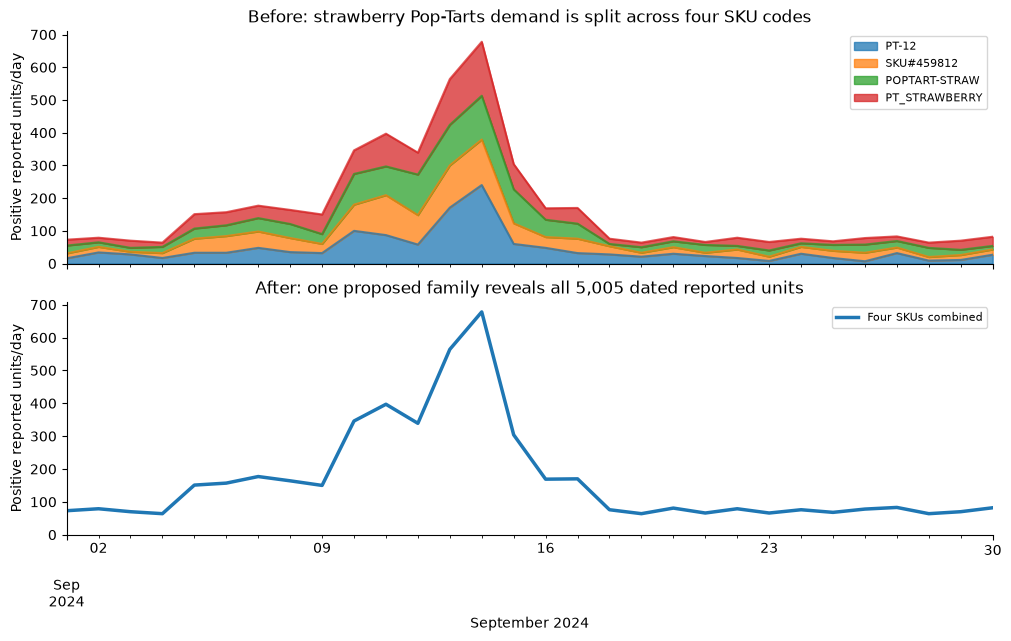

Q2: 45 SKUs -> 20 proposed families | 25,532 rows unchanged | 49,584 positive units unchanged
Pop-Tarts: 5,005 dated + 193 undated = 5,198 positive reported units


In [5]:
# Complete Q2: all 45 SKUs, proposed families, and a before/after daily plot.
FAMILIES = {
'Strawberry Pop-Tarts':['PT-12','SKU#459812','POPTART-STRAW','PT_STRAWBERRY'],
'Bottled Water (review pack size)':['WTR-24','WATER24PK','WTR_24PK'],
'AA Batteries (review pack size)':['BATT-100','BAT-AA4','BATT_AA_4PK'],
'LED Flashlight':['FLASH-01','LED-FLASH'], 'Light Beer':['BEER-24','LTBEER24'],
'Monopoly Board Game':['BG-MONO','MONOPOLY-01','GAME-MONO'],
'Playing Cards':['CARDS-01','PLAYCARD-STD'],
'Streaming Devices (review model)':['STREAM-01','ROKU-STD'],
'Canned Soup':['SOUP-CAN','CNSOUP-01'],
'White Bread':['BREAD-WH','WHITEBREAD'],
'Peanut Butter':['PB-16','PNUTBTR-16'],
'Emergency Candles':['CNDL-EM','CANDLE-EMRG'],
'First-Aid Kit':['FAID-01','FIRSTAID-KIT'],
'Portable Chargers':['CHRG-PORT','PORTCHARGER'],
'Chips Variety Pack':['CHIPS-VP','CHIPVARIETY'],
'Paper Towels':['PTOWEL-6','PAPERTOWEL6'],
'Toilet Paper':['TP-12','TOILETPAPER12'],
'Size 3 Diapers':['DIAP-S3','DIAPERS-3'],
'Baby Formula':['BFORM-01','BABYFORMULA'],
'Heavy-Duty Tarp':['TARP-HD','HDTARP-01']
}
family_lookup={sku:family for family,skus in FAMILIES.items() for sku in skus}
products=products_raw.copy()
products['sku_clean']=products['sku'].astype('string').str.strip().str.upper()
products['category_clean']=clean_category(products['category'])
assert len(family_lookup)==45 and len(FAMILIES)==20
assert products['sku_clean'].is_unique
assert set(products['sku_clean'])==set(family_lookup)
products['product_family']=products['sku_clean'].map(family_lookup)
products['mapping_status']='Proposed family - check package size and supplier'
q2_merged=clean.merge(products[['sku_clean','product_family']],on='sku_clean',how='left',validate='many_to_one',indicator=True)
assert len(q2_merged)==len(clean)==25532
assert q2_merged['_merge'].eq('both').all()
assert np.isclose(q2_merged.quantity_clean.sum(), clean.quantity_clean.sum())
q2_pos=q2_merged.loc[q2_merged.quantity_clean.gt(0)].copy()
assert q2_pos.quantity_clean.sum()==49584
codes=FAMILIES['Strawberry Pop-Tarts']
pop=q2_pos[q2_pos.sku_clean.isin(codes)]
pop_dated=pop.dropna(subset=['date'])
pop_undated=pop.loc[pop.date.isna(),'quantity_clean'].sum()
before=(pop_dated.pivot_table(index='date',columns='sku_clean',values='quantity_clean',aggfunc='sum',fill_value=0)
 .reindex(index=pd.date_range('2024-09-01','2024-09-30'),columns=codes,fill_value=0))
after=before.sum(axis=1)
assert after.sum()==5005 and pop_undated==193 and pop.quantity_clean.sum()==5198
assert np.isclose(before.to_numpy().sum(),after.sum())
fig,ax=plt.subplots(2,1,figsize=(10,6.3),sharex=True,layout='constrained')
before.plot.area(ax=ax[0],alpha=.75)
after.plot(ax=ax[1],lw=2.5,label='Four SKUs combined')
ax[0].set_title('Before: strawberry Pop-Tarts demand is split across four SKU codes')
ax[1].set_title('After: one proposed family reveals all 5,005 dated reported units')
for a in ax:
    a.set_ylabel('Positive reported units/day');a.set_ylim(bottom=0)
    a.spines[['top','right']].set_visible(False);a.legend(fontsize=8)
ax[1].set_xlabel('September 2024')
fig.savefig(OUT/'Mouad_Q2_before_after.png',dpi=170)
plt.show()
products.to_csv(DATA/'sku_mapping_MOUAD_AUDIT.csv',index=False)
print('Q2: 45 SKUs -> 20 proposed families | 25,532 rows unchanged | 49,584 positive units unchanged')
print('Pop-Tarts: 5,005 dated + 193 undated = 5,198 positive reported units')

### Q2 finding and limitations

Related product names were spread across different SKU codes. Strawberry Pop-Tarts appeared under four SKUs: together they totaled **5,198 positive reported units**, but only **5,005** had usable dates for the daily chart. The catalog has **45 SKUs grouped into 20 proposed families**. We checked that merging the mapping preserved all **25,532** cleaned rows and **49,584** positive reported units. A family grouping does **not** prove identical stocking units; the catalog lists inconsistent package sizes and suppliers, so a buyer would verify item identity before restocking.

In [6]:
# Visible SQLite schema inspection BEFORE Q5 queries.
db_path=DATA/'inventory_and_sales.db'
with sqlite3.connect(db_path) as conn:
    schema=pd.read_sql_query(
        "SELECT name, sql FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name", conn)
    print('SQL tables and CREATE statements:')
    display(schema)
    for tbl in ['daily_sales_summary','inventory_levels']:
        print('Columns in',tbl)
        display(pd.read_sql_query(f'PRAGMA table_info({tbl})',conn))
    source_dates=pd.read_sql_query('SELECT date FROM daily_sales_summary',conn)
    sql_dates_eight=int(source_dates.date.astype(str).str.fullmatch(r'\d{8}').sum())
    source_n=len(source_dates)
assert sql_dates_eight==218 and source_n==3600
print('Mixed-format SQL dates:',sql_dates_eight,'of',source_n)

SQL tables and CREATE statements:


,name,sql
0,daily_sales_summary,CREATE TABLE daily_sales_summary (\n date T...
1,inventory_levels,CREATE TABLE inventory_levels (\n date TEXT...


Columns in daily_sales_summary


,cid,name,type,notnull,dflt_value,pk
0,0,date,TEXT,0,None,0
1,1,store_id,TEXT,0,None,0
2,2,category,TEXT,0,None,0
3,3,total_units,REAL,0,None,0
4,4,total_revenue,REAL,0,None,0


Columns in inventory_levels


,cid,name,type,notnull,dflt_value,pk
0,0,date,TEXT,0,None,0
1,1,store_id,TEXT,0,None,0
2,2,sku,TEXT,0,None,0
3,3,units_on_hand,INTEGER,0,None,0
4,4,units_on_order,INTEGER,0,None,0
5,5,reorder_point,INTEGER,0,None,0


Mixed-format SQL dates: 218 of 3600


In [7]:
# Q5: Normalize SQLite dates in SQL and compare two separate sales data grains.
sales_query="""
WITH dates AS (
 SELECT CASE WHEN length(date)=8 AND date GLOB '[0-9][0-9][0-9][0-9][0-9][0-9][0-9][0-9]'
             THEN substr(date,1,4)||'-'||substr(date,5,2)||'-'||substr(date,7,2)
             ELSE date END AS clean_date, store_id, category,total_units,total_revenue
 FROM daily_sales_summary
)
SELECT clean_date AS date,store_id,category, SUM(total_units) AS total_units,SUM(total_revenue) AS total_revenue
FROM dates WHERE clean_date BETWEEN '2024-09-01' AND '2024-09-30'
GROUP BY clean_date,store_id,category
"""
with sqlite3.connect(db_path) as conn:
    sales=pd.read_sql_query(sales_query,conn)
    inventory=pd.read_sql_query("SELECT * FROM inventory_levels WHERE date BETWEEN '2024-09-01' AND '2024-09-30'",conn)
assert len(sales)==source_n==3600 and len(inventory)==4320
for df in [sales,inventory]:
    df['date']=pd.to_datetime(df.date)
    df['store_id_clean']=clean_store_id(df.store_id)
    unrecognized=set(df['store_id_clean'])-set(stores_clean['store_id_clean'])
    assert not unrecognized, f'Unrecognized DB store IDs: {unrecognized}'
    print('SQL table store IDs verified:',len(set(df['store_id_clean'])), 'unique, no unmatched')
sales['category_clean']=clean_category(sales.category)
inventory['sku_clean']=inventory.sku.astype('string').str.strip().str.upper()
inventory['product_family']=inventory['sku_clean'].map(family_lookup)
inventory['below_reorder']=inventory.units_on_hand.lt(inventory.reorder_point)
inventory['out_of_stock']=inventory.units_on_hand.le(0)
unknown=inventory.loc[inventory.product_family.isna(),'sku_clean']
assert len(unknown)==355
print('Inventory unknown-SKU records:',len(unknown),'codes:',unknown.unique().tolist())

calendar=pd.date_range('2024-09-01','2024-09-30')
sales_db=(sales.loc[sales.category_clean.eq('Entertainment')]
          .groupby('date').total_units.sum().reindex(calendar,fill_value=0))
sales_csv=(clean.loc[clean.date.notna() & clean.quantity_clean.gt(0) & clean.category_clean.eq('Entertainment')]
           .groupby('date').quantity_clean.sum().reindex(calendar,fill_value=0))
def avg(series,a,b):return series.loc[a:b].mean()
baseline=('2024-09-01','2024-09-04');spike=('2024-09-10','2024-09-14')
q5_results=pd.DataFrame({
 'source':['SQLite category summary','Cleaned transaction CSV'],
 'baseline_per_day':[avg(sales_db,*baseline),avg(sales_csv,*baseline)],
 'spike_per_day':[avg(sales_db,*spike),avg(sales_csv,*spike)]
})
q5_results['pct_increase']=(q5_results.spike_per_day/q5_results.baseline_per_day-1)*100
assert np.isclose(q5_results.loc[0,'pct_increase'],185.36,atol=.05)
assert np.isclose(q5_results.loc[1,'pct_increase'],191.66,atol=.05)
print('Source comparison:')
display(q5_results.round(2))
print('Daily correlation of the source series:',round(sales_db.corr(sales_csv),3))
monopoly_codes=set(FAMILIES['Monopoly Board Game'])
monopoly_daily=(q2_pos.loc[q2_pos.sku_clean.isin(monopoly_codes) & q2_pos.date.notna()]
    .groupby('date').quantity_clean.sum().reindex(calendar,fill_value=0))
monopoly_baseline=avg(monopoly_daily,*baseline)
monopoly_spike=avg(monopoly_daily,*spike)
monopoly_growth=(monopoly_spike/monopoly_baseline-1)*100
assert np.isclose(monopoly_baseline,37.75) and np.isclose(monopoly_spike,134.8)
print('Monopoly reported units/day:',monopoly_baseline,'->',monopoly_spike,
      '| increase %:',round(monopoly_growth,2))

ent_codes=set(products.loc[products.category_clean.eq('Entertainment'),'sku_clean'])
ent=inventory.loc[inventory.sku_clean.isin(ent_codes)].copy()
ent['period']=np.select([ent.date.between(*baseline),ent.date.between(*spike)],['baseline','spike'],default='other')
audit=(ent.groupby('period').agg(snapshots=('sku_clean','size'),below=('below_reorder','sum'),stockout=('out_of_stock','sum')))
audit['below_pct']=100*audit.below/audit.snapshots
assert audit.loc['baseline','snapshots']==63 and audit.loc['baseline','below']==0
assert audit.loc['spike','snapshots']==71 and audit.loc['spike','below']==41
assert ent['out_of_stock'].sum()==0
print('Inventory audit:');display(audit.round(2))
# Note: category-level SQLite sales cannot be assumed to have the same unit basis as transaction CSV.

SQL table store IDs verified: 12 unique, no unmatched
SQL table store IDs verified: 12 unique, no unmatched
Inventory unknown-SKU records: 355 codes: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']
Source comparison:


,source,baseline_per_day,spike_per_day,pct_increase
0,SQLite category summary,576.00,1643.7,185.36
1,Cleaned transaction CSV,91.75,267.6,191.66


Daily correlation of the source series: 0.958
Monopoly reported units/day: 37.75 -> 134.8 | increase %: 257.09
Inventory audit:


,snapshots,below,stockout,below_pct
period,,,,
baseline,63,0,0,0.00
other,312,50,0,16.03
spike,71,41,0,57.75


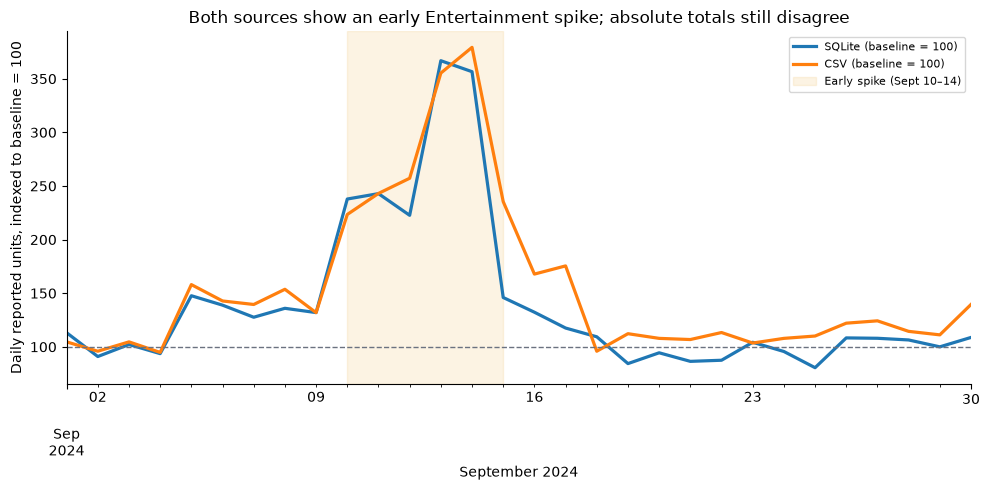

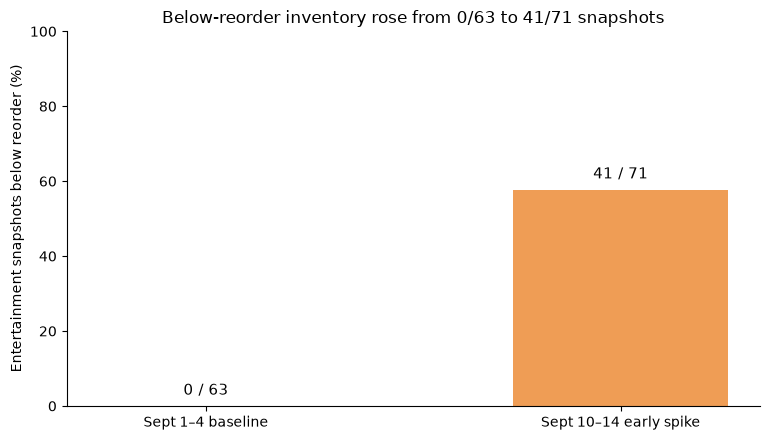

In [8]:
# Q5 source comparison chart and verified inventory pressure graphic.
fig,ax=plt.subplots(figsize=(10,5))
idx=pd.DataFrame({
    'SQLite (baseline = 100)':100*sales_db/q5_results.loc[0,'baseline_per_day'],
    'CSV (baseline = 100)':100*sales_csv/q5_results.loc[1,'baseline_per_day']
})
idx.plot(ax=ax,lw=2.3)
ax.axhline(100,ls='--',color='#6b7280',lw=1)
ax.axvspan(pd.Timestamp('2024-09-10'),pd.Timestamp('2024-09-15'),color='#F3C97F',alpha=.21,label='Early spike (Sept 10–14)')
ax.set(title='Both sources show an early Entertainment spike; absolute totals still disagree',
       xlabel='September 2024',ylabel='Daily reported units, indexed to baseline = 100')
ax.spines[['top','right']].set_visible(False)
ax.legend(loc='upper right',fontsize=8)
fig.tight_layout();fig.savefig(OUT/'Mouad_Q5_SQL_vs_CSV_indexed.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(7.8,4.5))
bars=ax.bar(['Sept 1–4 baseline','Sept 10–14 early spike'],
            [audit.loc['baseline','below_pct'],audit.loc['spike','below_pct']],
            color=['#7BA4B6','#EF9D55'],width=.52)
ax.set_ylim(0,100);ax.set_ylabel('Entertainment snapshots below reorder (%)')
ax.set_title('Below-reorder inventory rose from 0/63 to 41/71 snapshots')
for b,lab in zip(bars,['0 / 63','41 / 71']):ax.text(b.get_x()+b.get_width()/2,b.get_height()+3,lab,ha='center',fontsize=11)
ax.spines[['top','right']].set_visible(False)
fig.tight_layout();fig.savefig(OUT/'Mouad_Q5_inventory_pressure.png',dpi=180);plt.show()
q5_results.to_csv(OUT/'Mouad_Q5_sources.csv',index=False)
audit.to_csv(OUT/'Mouad_Q5_inventory_audit.csv')

### Q5 finding and recommendation

The early **September 10–14**, 2024 Entertainment spike appears in both the transaction CSV (**+191.7%**) and the SQLite category summary (**+185.4%**) relative to September 1–4. Monopoly alone rose **+257.1%** in cleaned CSV reported units. During the spike, **41/71** Entertainment inventory snapshots fell below reorder points, versus **0/63** at baseline; no observed zero-stock snapshots. However, the sources do **not** agree in absolute units, and 355 inventory records have codes missing from the catalog. **Recommendation:** monitor and replenish items already below reorder, try only a modest targeted additional buffer after verifying SKU sizes and reporting conventions. This is an observed spike, **not proof of hurricane causation**.

In [9]:
# One comprehensive, source-aware decision log. Counts are distinct issues, not additive.
log_rows=[]
def log(file,issue,decision,affected,reason):
    log_rows.append({'file':file,'issue':issue,'decision':decision,
                    'rows_affected':int(affected),'reason':reason})
log('walmart_transactions.csv','Exact duplicate rows','Remove exact duplicates',len(raw)-len(clean),
    'Avoid double-counted sales; all other records preserved')
log('walmart_transactions.csv','Missing or unusable timestamps','Keep in cleaned data; exclude only from day-level comparisons',int(clean.date.isna().sum()),
    'Cannot assign an unknown purchase to a particular calendar day')
log('walmart_transactions.csv','Negative reported quantities','Flag as possible returns; omit from gross positive-demand totals',int(clean.possible_return.sum()),
    'Returns/adjustments are not new positive demand')
log('walmart_transactions.csv','Inconsistent store ID formatting','Trim/case-normalize; unify FL-### aliases',int(clean.store_id.astype('string').ne(clean_store_id(clean.store_id)).fillna(False).sum()),
    'Allows valid store-reference joins without dropping transactions')
log('walmart_transactions.csv','Category label inconsistencies','Trim/title-case and apply documented category aliases',int(clean.category.astype('string').ne(clean_category(clean.category)).fillna(False).sum()),
    'Allows meaningful category comparison')
log('walmart_transactions.csv','Formatted price strings','Remove $/commas; parse numeric and flag failures',int(raw.unit_price.astype('string').str.contains(r'\$|^\s|\s$',regex=True,na=False).sum()),
    'Prevents text prices from corrupting summaries')
log('store_locations.csv','Duplicate alias rows for stores','Normalize store IDs; collapse agreeing duplicate references',len(stores_raw)-len(stores_clean),
    'Creates one unique store reference for many-to-one joins')
log('store_locations.csv','State written Florida or Fla.','Normalize all Florida labels to FL',store_states_changed,
    'Consistent location metadata')
log('store_locations.csv','Region whitespace','Strip leading/trailing region spaces',regions_trimmed,
    'Avoids creating phantom regions')
log('store_locations.csv','Tallahassee missing latitude/longitude','Keep store in sales; exclude from geographic distance calculations',int(missing_geo.sum()),
    'Do not invent coordinates')
log('product_catalog.csv','SKU aliases and naming variants','Propose 20 families across all 45 SKUs; retain original SKU/supplier/size',len(products),
    'Makes family-level demand visible without asserting all packages identical')
log('product_catalog.csv','Conflicting package-size descriptions','Flag for verification; do not convert packages into assumed item counts',int(products.groupby('product_family').package_size.transform('nunique').gt(1).sum()),
    'Unreliable units-per-package text can cause false stock counts')
log('distribution_centers.csv','Approximate surge capacity ~750','Keep raw text and approximate hint; exact capacity remains missing',int(dc.surge_capacity_is_approx.sum()),
    'Tilde means estimate, not exact planning limit')
log('distribution_centers.csv','Missing cost per shipment','Keep missing; no zero or mean imputation',int(dc.cost_per_shipment_clean.isna().sum()),
    'An invented shipment cost would distort comparisons')
log('inventory_and_sales.db / daily_sales_summary','Mixed 8/10-character date formats','Normalize eight-digit dates in SQL before date filtering',sql_dates_eight,
    'Prevents silent loss of 218 category sales rows')
log('inventory_and_sales.db / inventory_levels','Inventory SKU absent from catalog','Flag unknown codes and preserve inventory snapshots',len(unknown),
    'Legacy/miscellaneous codes cannot be assumed to match specific products')
log('inventory_and_sales.db','Check store ID references in both SQL tables','Normalize identifiers; assert match to 12 cleaned stores',len(sales)+len(inventory),
    'Verifies store join compatibility; zero unmatched IDs')
log('CSV versus SQLite','Absolute Entertainment unit totals disagree','Compare indexed trends, retain both sources; do not equate level totals',len(sales_db),
    'Reporting grain or unit conventions are unresolved')
decision_log_full=pd.DataFrame(log_rows)
assert set(decision_log_full.file.str.split(' / ').str[0]).issuperset({
 'walmart_transactions.csv','store_locations.csv','product_catalog.csv',
 'distribution_centers.csv','inventory_and_sales.db','CSV versus SQLite'})
assert decision_log_full.rows_affected.notna().all()
print('Decision log entries:',len(decision_log_full))
display(decision_log_full)
decision_log_full.to_csv(DATA/'decision_log_full_review.csv',index=False)
print('Saved:',DATA/'decision_log_full_review.csv')

Decision log entries: 18


,file,issue,decision,rows_affected,reason
0,walmart_transactions.csv,Exact duplicate rows,Remove exact duplicates,30,Avoid double-counted sales; all other records ...
1,walmart_transactions.csv,Missing or unusable timestamps,Keep in cleaned data; exclude only from day-le...,884,Cannot assign an unknown purchase to a particu...
2,walmart_transactions.csv,Negative reported quantities,Flag as possible returns; omit from gross posi...,130,Returns/adjustments are not new positive demand
3,walmart_transactions.csv,Inconsistent store ID formatting,Trim/case-normalize; unify FL-### aliases,4345,Allows valid store-reference joins without dro...
4,walmart_transactions.csv,Category label inconsistencies,Trim/title-case and apply documented category ...,18744,Allows meaningful category comparison
5,walmart_transactions.csv,Formatted price strings,Remove $/commas; parse numeric and flag failures,4332,Prevents text prices from corrupting summaries
6,store_locations.csv,Duplicate alias rows for stores,Normalize store IDs; collapse agreeing duplica...,2,Creates one unique store reference for many-to...
7,store_locations.csv,State written Florida or Fla.,Normalize all Florida labels to FL,4,Consistent location metadata
8,store_locations.csv,Region whitespace,Strip leading/trailing region spaces,1,Avoids creating phantom regions
9,store_locations.csv,Tallahassee missing latitude/longitude,Keep store in sales; exclude from geographic d...,1,Do not invent coordinates


Saved: c:\Users\mouad\F26-DS2002-Midterm-Repo-Nate-Mohamed-Mouad\data\decision_log_full_review.csv


In [10]:
# Final independent checklist.
assert len(clean)==25532
assert len(stores_clean)==12 and stores_clean.state_clean.eq('FL').all()
assert products.product_family.nunique()==20
assert len(sales)==3600 and len(inventory)==4320
assert len(unknown)==355
assert audit.loc['spike','below']==41
assert (DATA/'decision_log_full_review.csv').is_file()
for filename in ['Mouad_Q2_before_after.png','Mouad_Q5_SQL_vs_CSV_indexed.png','Mouad_Q5_inventory_pressure.png']:
    assert (OUT/filename).is_file(),filename
print('PASS — original source files unchanged; Q2, Q5, store/DC cleaning, SQL audits, and shared log ready for review.')

PASS — original source files unchanged; Q2, Q5, store/DC cleaning, SQL audits, and shared log ready for review.
